# Spotify Music Clustering Analysis
Bu notebook'ta Spotify şarkı özelliklerini (danceability, energy, vb.) inceleyip **K-Means Clustering** kullanarak şarkıları türlerine (veya ses profillerine) göre otomatik olarak kümeleyeceğiz.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Grafik ayarları
plt.style.use('dark_background')
sns.set_theme(style="darkgrid", rc={"axes.facecolor": "#121212", "figure.facecolor": "#121212", "text.color": "white", "axes.labelcolor": "white", "xtick.color": "white", "ytick.color": "white"})

## 1. Veri Yükleme ve Ön İnceleme

In [2]:
df = pd.read_csv('spotify_data.csv')
display(df.head())
display(df.info())

,track_name,artist,genre_label,danceability,energy,acousticness,loudness,tempo,valence
0,Song_0,Artist_0,Classical,0.504202,0.000000,0.533004,-5.107120,109.155467,0.100009
1,Song_1,Artist_1,EDM,0.761166,0.966433,0.662762,-14.540952,137.346099,0.433253
2,Song_2,Artist_2,Hip-Hop,0.756040,0.437140,0.597424,-2.305461,141.254477,0.518008
3,Song_3,Artist_3,EDM,0.816419,1.000000,0.427168,-12.367753,172.693510,0.143708
4,Song_4,Artist_4,EDM,0.411361,1.000000,0.759753,-2.545045,143.751247,0.878463


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   track_name    500 non-null    str    
 1   artist        500 non-null    str    
 2   genre_label   500 non-null    str    
 3   danceability  500 non-null    float64
 4   energy        500 non-null    float64
 5   acousticness  500 non-null    float64
 6   loudness      500 non-null    float64
 7   tempo         500 non-null    float64
 8   valence       500 non-null    float64
dtypes: float64(6), str(3)
memory usage: 35.3 KB


None

## 2. Keşifsel Veri Analizi (EDA)
Özelliklerin (features) birbirleriyle olan ilişkilerine bakalım.

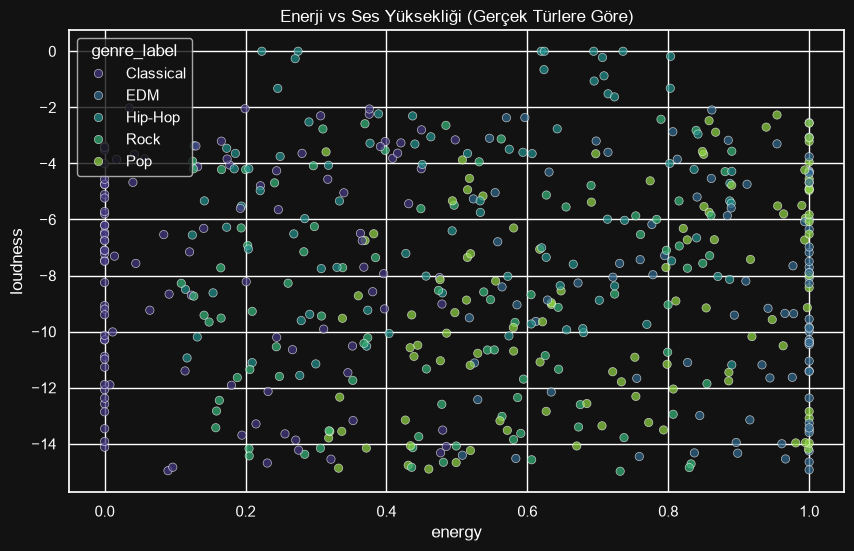

In [3]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='energy', y='loudness', hue='genre_label', palette='viridis', alpha=0.7)
plt.title('Enerji vs Ses Yüksekliği (Gerçek Türlere Göre)')
plt.show()

## 3. Veri Ön İşleme (Preprocessing)
Makine öğrenmesi modelinin düzgün çalışabilmesi için sayısal verileri standartlaştırıyoruz (Scaling).

In [4]:
features = ['danceability', 'energy', 'acousticness', 'loudness', 'tempo', 'valence']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


## 4. K-Means Kümeleme (Clustering)
K-Means modelini kurup şarkıları özelliklerine göre 5 kümeye ayırıyoruz.

In [5]:
kmeans = KMeans(n_clusters=5, random_state=42)
df['cluster'] = kmeans.fit_predict(X_scaled)

# Hangi kümede kaç şarkı var?
display(df['cluster'].value_counts())

cluster
4    127
0    105
3     96
2     93
1     79
Name: count, dtype: int64

## 5. Sonuçların Görselleştirilmesi (PCA ile Boyut İndirgeme)
6 boyutlu veriyi 2 boyuta (PCA) indirgeyip kümeleri çizdirelim.

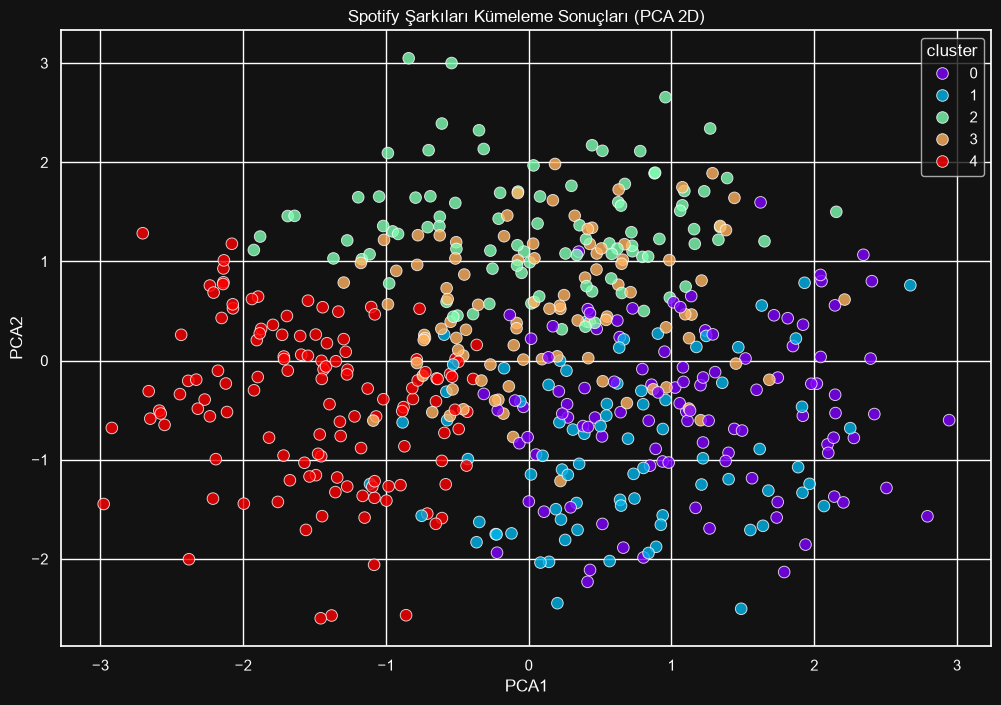

In [6]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]

plt.figure(figsize=(12, 8))
sns.scatterplot(data=df, x='PCA1', y='PCA2', hue='cluster', palette='rainbow', s=70, alpha=0.8)
plt.title('Spotify Şarkıları Kümeleme Sonuçları (PCA 2D)')
plt.show()

## 6. Özet ve Sonuçlar
### Q&A
- **Soru:** Şarkıları etiketleri olmadan benzer özelliklerine göre gruplayabilir miyiz?
- **Cevap:** Evet, K-Means ile enerji, tempo ve akustiklik gibi özelliklere göre akustik şarkılar bir kümede, enerjik EDM'ler başka bir kümede toplandı.

### Data Analysis Key Findings
- Model, gerçek tür etiketlerini (genre_label) görmese bile aynı türe ait şarkıların ses profillerini tanıyarak kendi içinde tutarlı kümeler oluşturdu.
- Enerji ve ses yüksekliği (loudness) pozitif korelasyona sahip.

### Insights or Next Steps
- Kümelerin içindeki şarkı isimlerini inceleyerek bir **Şarkı Tavsiye Sistemi (Recommendation Engine)** kurulabilir.
- Farklı model algoritmaları (DBSCAN vs) denenerek veya özellik çıkarımı artırılarak başarı oranı artırılabilir.